In [ ]:
!pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 9.3 MB/s eta 0:00:00


Processing...
Done!
Processing...
Done!
Processing...
Done!


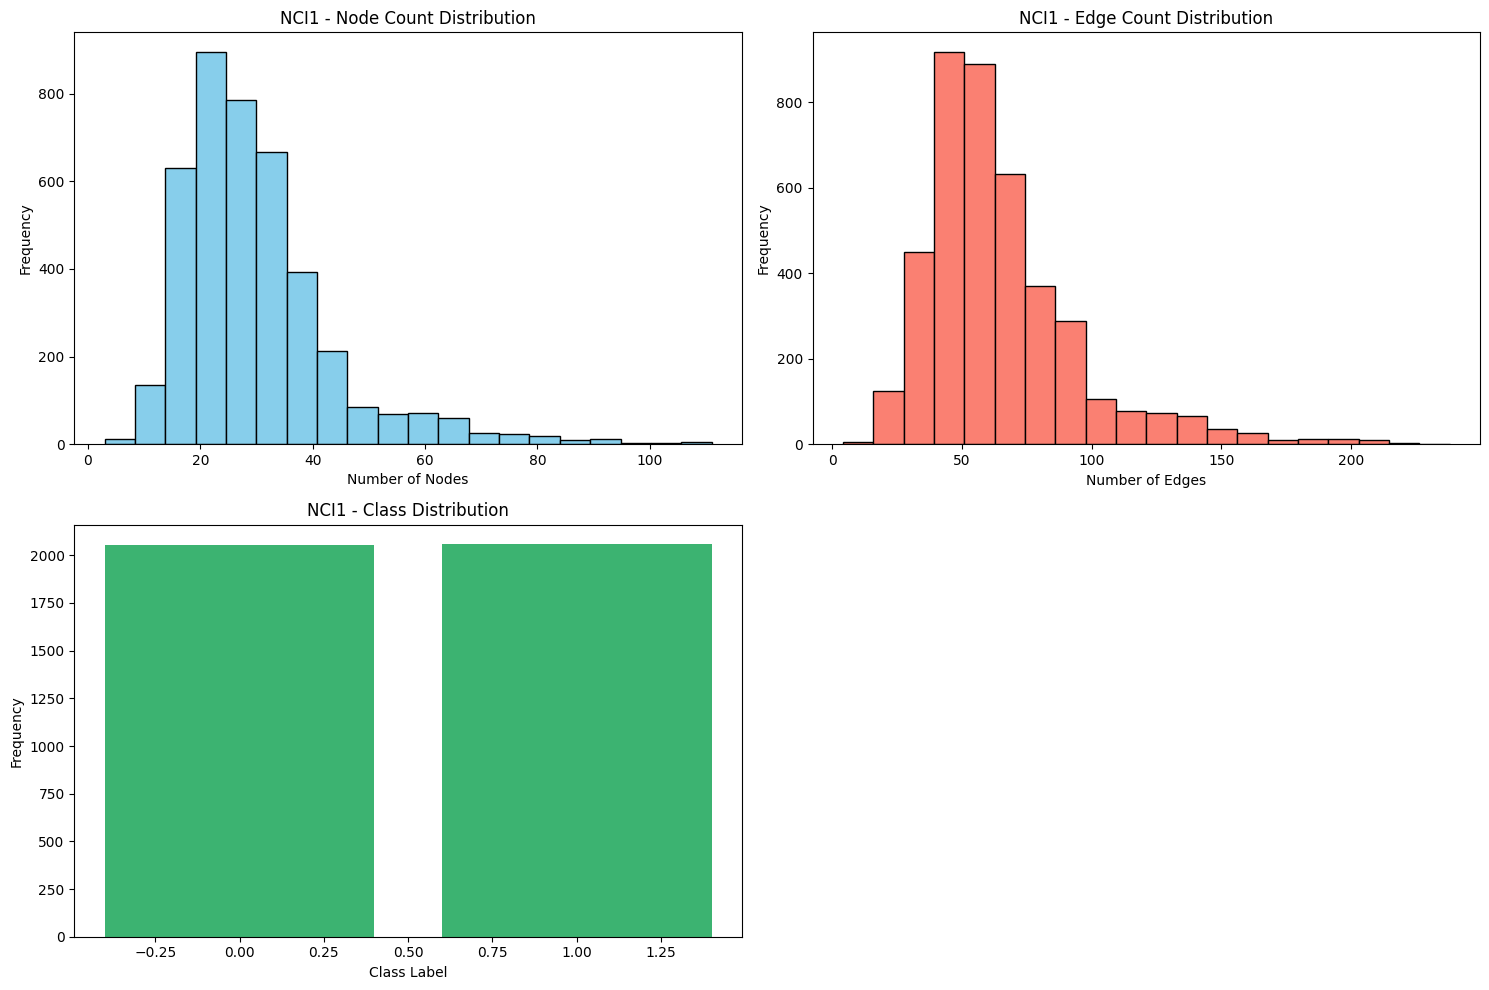

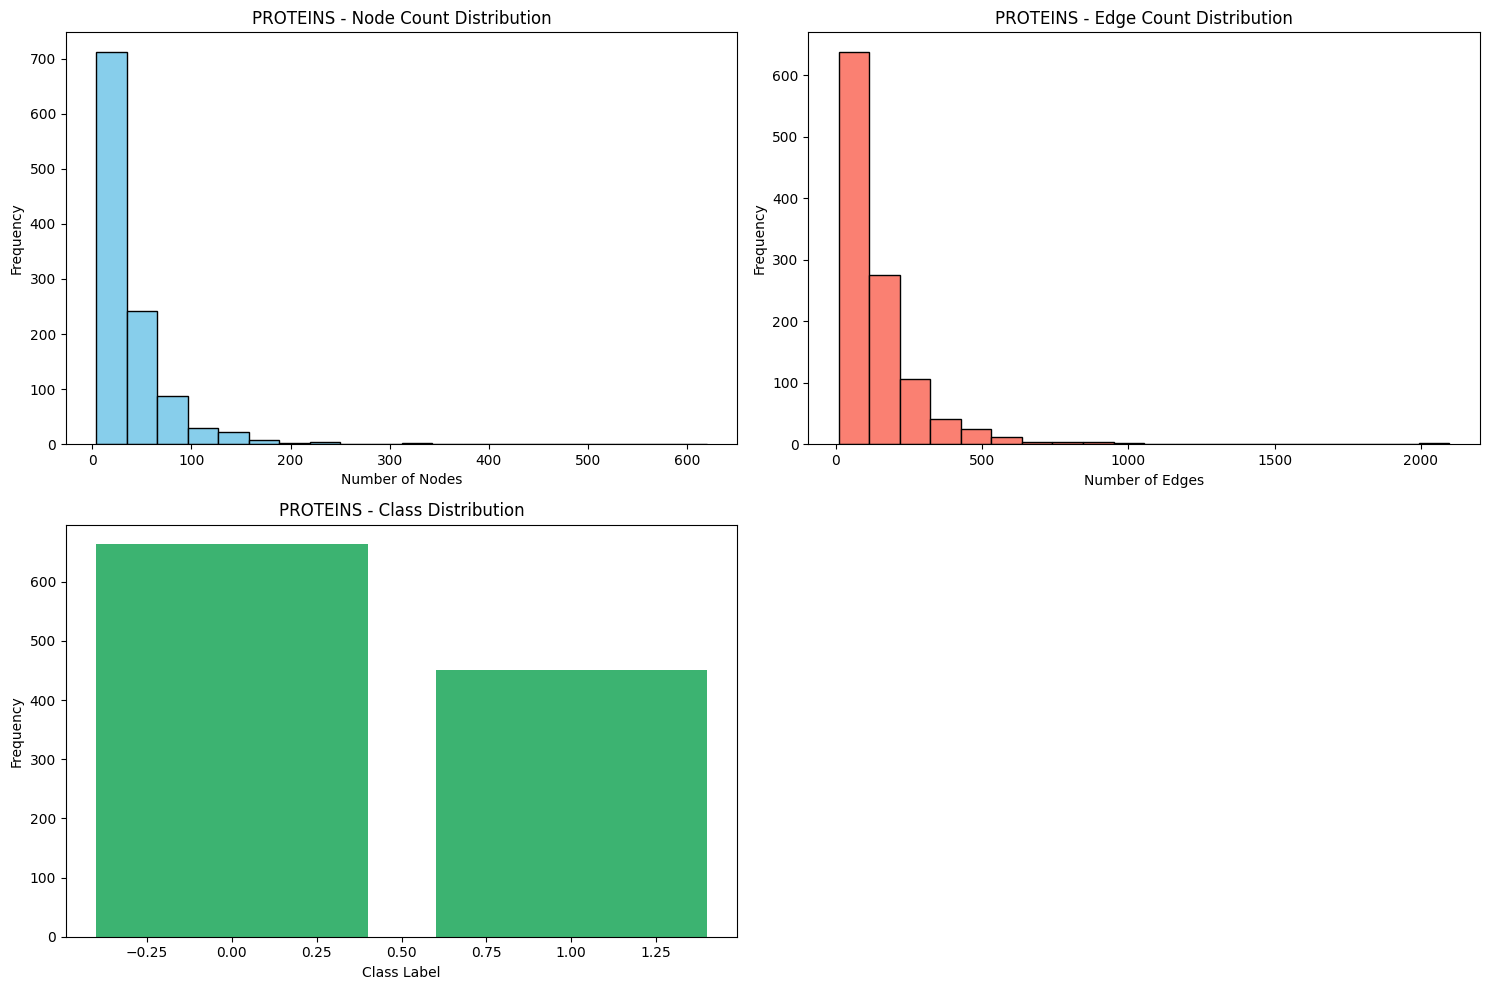

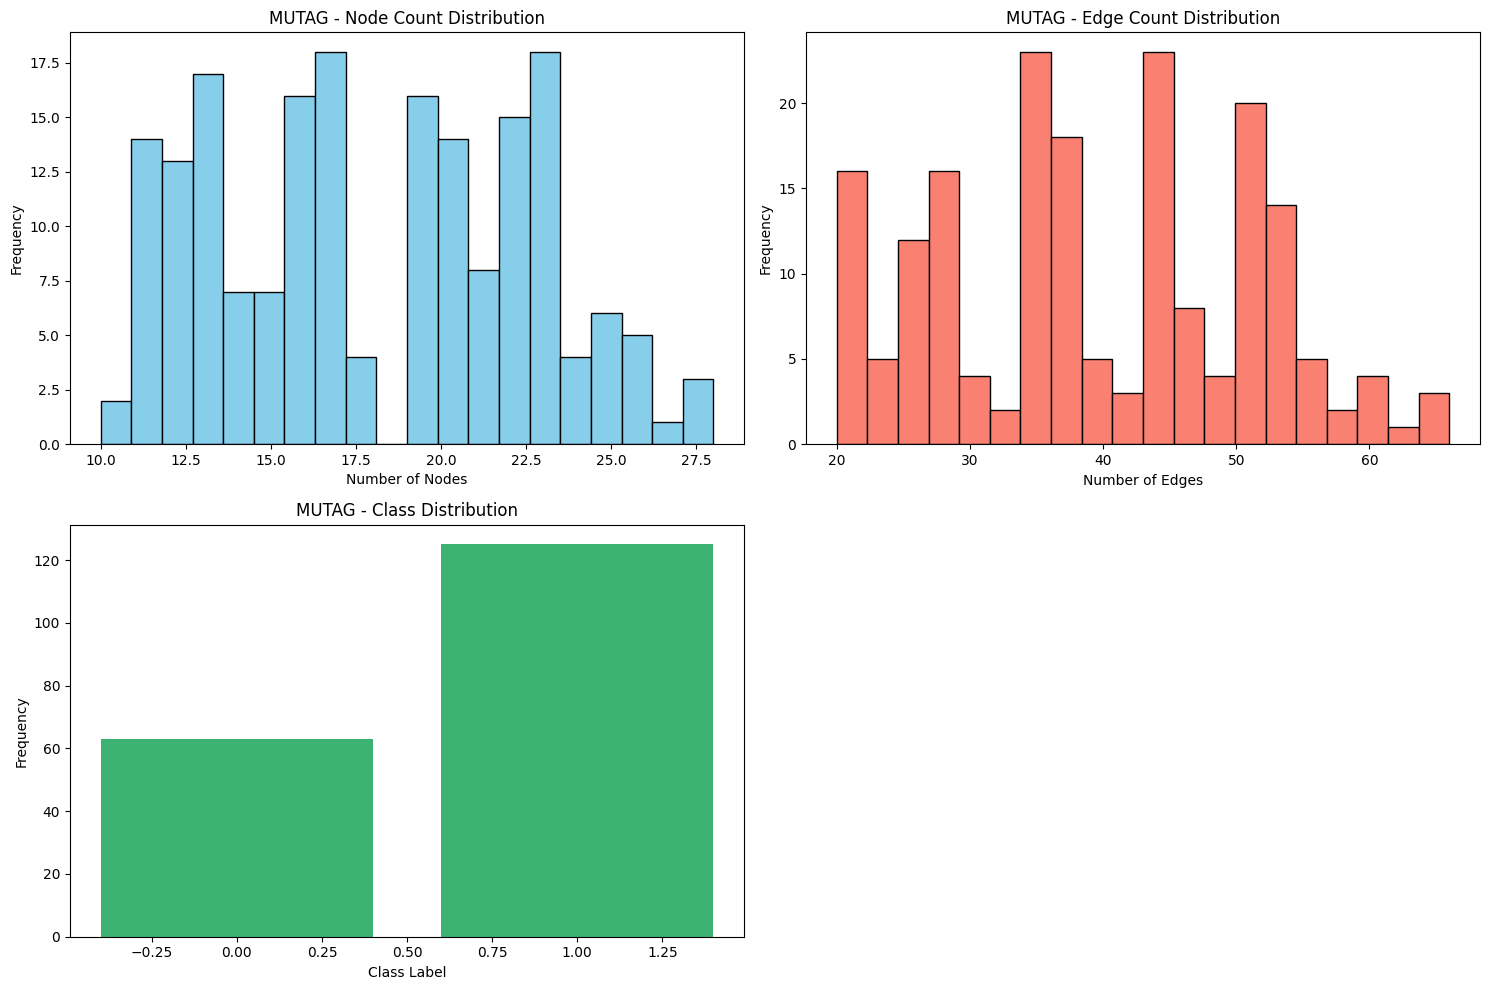

In [ ]:

# Import necessary libraries
import torch
from torch_geometric.datasets import TUDataset
from torch_geometric.transforms import NormalizeFeatures
import matplotlib.pyplot as plt
import numpy as np

# Load the datasets
datasets = {
    'NCI1': TUDataset(root='/tmp/NCI1', name='NCI1', transform=NormalizeFeatures()),
    'PROTEINS': TUDataset(root='/tmp/PROTEINS', name='PROTEINS', transform=NormalizeFeatures()),
    'MUTAG': TUDataset(root='/tmp/MUTAG', name='MUTAG', transform=NormalizeFeatures())
}

# Function to calculate dataset properties
def calculate_properties(dataset):
    num_nodes = [data.num_nodes for data in dataset]
    num_edges = [data.num_edges for data in dataset]
    num_classes = dataset.num_classes
    class_distribution = np.bincount([data.y.item() for data in dataset], minlength=num_classes)

    return {
        'num_nodes': num_nodes,
        'num_edges': num_edges,
        'class_distribution': class_distribution
    }

# Function to plot dataset properties
def plot_properties(dataset_name, properties):
    # Plot number of nodes distribution
    plt.figure(figsize=(15, 10))
    plt.subplot(2, 2, 1)
    plt.hist(properties['num_nodes'], bins=20, color='skyblue', edgecolor='black')
    plt.title(f'{dataset_name} - Node Count Distribution')
    plt.xlabel('Number of Nodes')
    plt.ylabel('Frequency')

    # Plot number of edges distribution
    plt.subplot(2, 2, 2)
    plt.hist(properties['num_edges'], bins=20, color='salmon', edgecolor='black')
    plt.title(f'{dataset_name} - Edge Count Distribution')
    plt.xlabel('Number of Edges')
    plt.ylabel('Frequency')

    # Plot class distribution
    plt.subplot(2, 2, 3)
    plt.bar(range(len(properties['class_distribution'])), properties['class_distribution'], color='mediumseagreen')
    plt.title(f'{dataset_name} - Class Distribution')
    plt.xlabel('Class Label')
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

# Calculate and plot properties for each dataset
for name, dataset in datasets.items():
    properties = calculate_properties(dataset)
    plot_properties(name, properties)


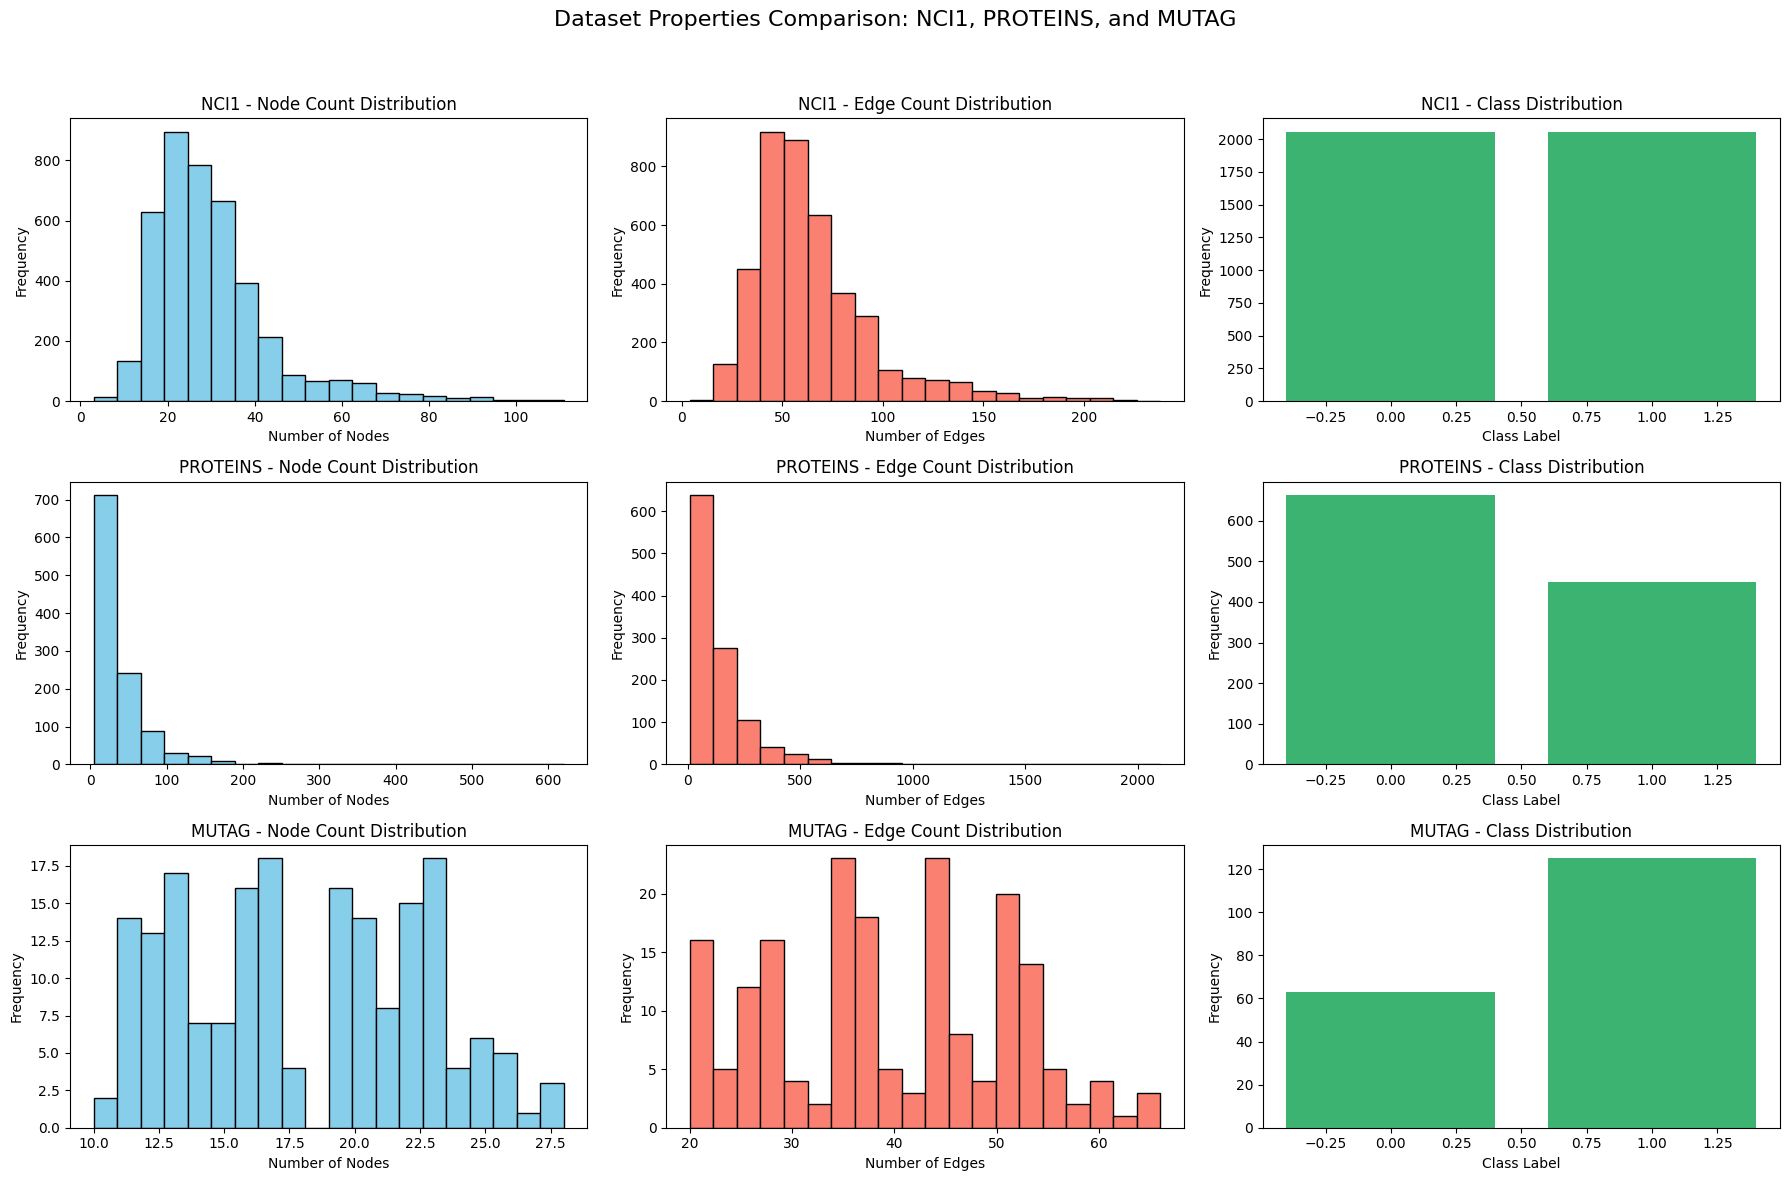

In [ ]:
# Import necessary libraries
import torch
from torch_geometric.datasets import TUDataset
from torch_geometric.transforms import NormalizeFeatures
import matplotlib.pyplot as plt
import numpy as np

# Load the datasets
datasets = {
    'NCI1': TUDataset(root='/tmp/NCI1', name='NCI1', transform=NormalizeFeatures()),
    'PROTEINS': TUDataset(root='/tmp/PROTEINS', name='PROTEINS', transform=NormalizeFeatures()),
    'MUTAG': TUDataset(root='/tmp/MUTAG', name='MUTAG', transform=NormalizeFeatures())
}

# Function to calculate dataset properties
def calculate_properties(dataset):
    num_nodes = [data.num_nodes for data in dataset]
    num_edges = [data.num_edges for data in dataset]
    num_classes = dataset.num_classes
    class_distribution = np.bincount([data.y.item() for data in dataset], minlength=num_classes)

    return {
        'num_nodes': num_nodes,
        'num_edges': num_edges,
        'class_distribution': class_distribution
    }

# Plot dataset properties in a single, compact figure
fig, axes = plt.subplots(len(datasets), 3, figsize=(18, 12))
fig.suptitle("Dataset Properties Comparison: NCI1, PROTEINS, and MUTAG", fontsize=16)

# Calculate and plot properties for each dataset
for i, (name, dataset) in enumerate(datasets.items()):
    properties = calculate_properties(dataset)

    # Plot number of nodes distribution
    axes[i, 0].hist(properties['num_nodes'], bins=20, color='skyblue', edgecolor='black')
    axes[i, 0].set_title(f'{name} - Node Count Distribution')
    axes[i, 0].set_xlabel('Number of Nodes')
    axes[i, 0].set_ylabel('Frequency')

    # Plot number of edges distribution
    axes[i, 1].hist(properties['num_edges'], bins=20, color='salmon', edgecolor='black')
    axes[i, 1].set_title(f'{name} - Edge Count Distribution')
    axes[i, 1].set_xlabel('Number of Edges')
    axes[i, 1].set_ylabel('Frequency')

    # Plot class distribution
    axes[i, 2].bar(range(len(properties['class_distribution'])), properties['class_distribution'], color='mediumseagreen')
    axes[i, 2].set_title(f'{name} - Class Distribution')
    axes[i, 2].set_xlabel('Class Label')
    axes[i, 2].set_ylabel('Frequency')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

array([<Axes: title={'center': 'Node Count Distribution'}, xlabel='Number of Nodes', ylabel='Frequency'>,
       <Axes: title={'center': 'Edge Count Distribution'}, xlabel='Number of Edges', ylabel='Frequency'>,
       <Axes: title={'center': 'Total Number of Graphs'}, ylabel='Total Graphs Count'>],
      dtype=object)

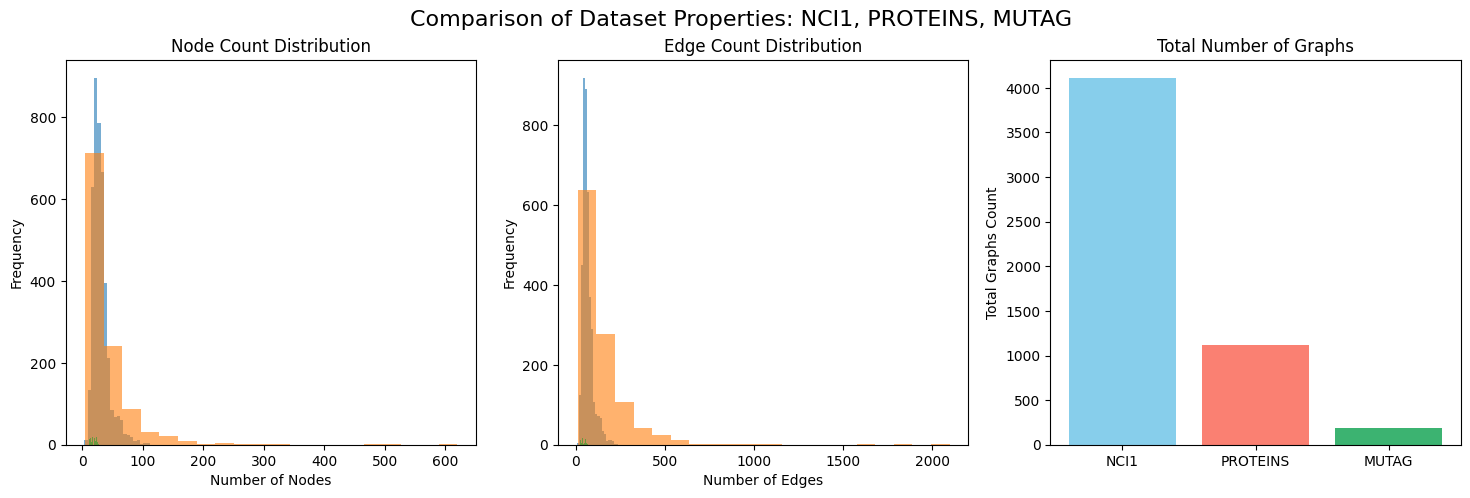

In [ ]:
# Install required libraries
!pip install torch_geometric matplotlib

# Import necessary libraries
import torch
from torch_geometric.datasets import TUDataset
from torch_geometric.transforms import NormalizeFeatures
import matplotlib.pyplot as plt
import numpy as np

# Load the datasets
datasets = {
    'NCI1': TUDataset(root='/tmp/NCI1', name='NCI1', transform=NormalizeFeatures()),
    'PROTEINS': TUDataset(root='/tmp/PROTEINS', name='PROTEINS', transform=NormalizeFeatures()),
    'MUTAG': TUDataset(root='/tmp/MUTAG', name='MUTAG', transform=NormalizeFeatures())
}

# Function to calculate dataset properties
def calculate_properties(dataset):
    num_nodes = [data.num_nodes for data in dataset]
    num_edges = [data.num_edges for data in dataset]
    total_graphs = len(dataset)

    return {
        'num_nodes': num_nodes,
        'num_edges': num_edges,
        'total_graphs': total_graphs
    }

# Initialize figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Comparison of Dataset Properties: NCI1, PROTEINS, MUTAG", fontsize=16)

# Collect properties for each dataset and plot
total_graphs_data = []
labels = []

for i, (name, dataset) in enumerate(datasets.items()):
    properties = calculate_properties(dataset)
    labels.append(name)

    # Plot distribution of number of nodes per graph
    axes[0].hist(properties['num_nodes'], bins=20, alpha=0.6, label=name)
    axes[0].set_title('Node Count Distribution')
    axes[0].set_xlabel('Number of Nodes')
    axes[0].set_ylabel('Frequency')

    # Plot distribution of number of edges per graph
    axes[1].hist(properties['num_edges'], bins=20, alpha=0.6, label=name)
    axes[1].set_title('Edge Count Distribution')
    axes[1].set_xlabel('Number of Edges')
    axes[1].set_ylabel('Frequency')

    # Add total number of graphs to the bar chart data
    total_graphs_data.append(properties['total_graphs'])

# Plot total number of graphs per dataset as bar chart
axes[2].bar(labels, total_graphs_data, color=['skyblue', 'salmon', 'mediumseagreen'])
axes[2].set_title('Total Number of Graphs')
axes[2].set_ylabel('Total Graphs Count')
axes


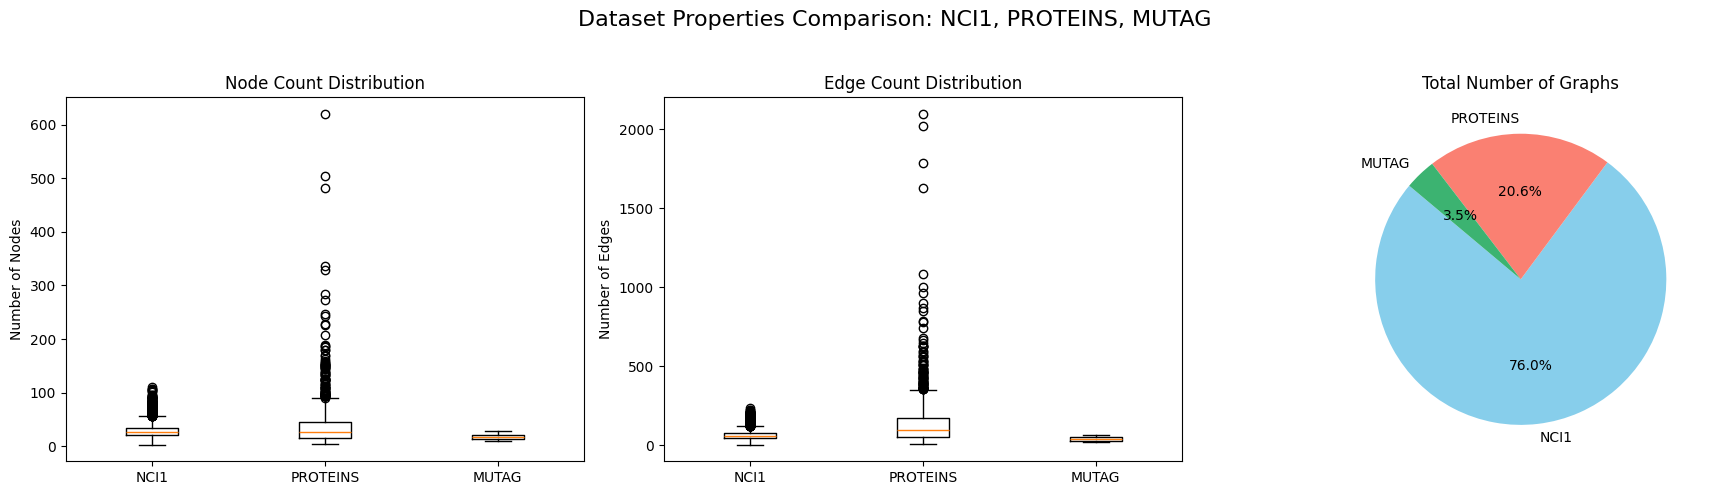

In [ ]:
# Install required libraries
!pip install torch_geometric matplotlib

# Import necessary libraries
import torch
from torch_geometric.datasets import TUDataset
from torch_geometric.transforms import NormalizeFeatures
import matplotlib.pyplot as plt

# Load the datasets
datasets = {
    'NCI1': TUDataset(root='/tmp/NCI1', name='NCI1', transform=NormalizeFeatures()),
    'PROTEINS': TUDataset(root='/tmp/PROTEINS', name='PROTEINS', transform=NormalizeFeatures()),
    'MUTAG': TUDataset(root='/tmp/MUTAG', name='MUTAG', transform=NormalizeFeatures())
}

# Function to calculate dataset properties
def calculate_properties(dataset):
    num_nodes = [data.num_nodes for data in dataset]
    num_edges = [data.num_edges for data in dataset]
    total_graphs = len(dataset)

    return {
        'num_nodes': num_nodes,
        'num_edges': num_edges,
        'total_graphs': total_graphs
    }

# Initialize figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Dataset Properties Comparison: NCI1, PROTEINS, MUTAG", fontsize=16)

# Collect properties for each dataset
properties_data = {}
for name, dataset in datasets.items():
    properties_data[name] = calculate_properties(dataset)

# Plot box plot for number of nodes per graph
axes[0].boxplot([properties_data[name]['num_nodes'] for name in datasets.keys()], labels=datasets.keys())
axes[0].set_title('Node Count Distribution')
axes[0].set_ylabel('Number of Nodes')

# Plot box plot for number of edges per graph
axes[1].boxplot([properties_data[name]['num_edges'] for name in datasets.keys()], labels=datasets.keys())
axes[1].set_title('Edge Count Distribution')
axes[1].set_ylabel('Number of Edges')

# Plot pie chart for total number of graphs in each dataset
total_graph_counts = [properties_data[name]['total_graphs'] for name in datasets.keys()]
axes[2].pie(total_graph_counts, labels=datasets.keys(), autopct='%1.1f%%', startangle=140, colors=['skyblue', 'salmon', 'mediumseagreen'])
axes[2].set_title('Total Number of Graphs')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 18.4 MB/s eta 0:00:00


Processing...
Done!
Processing...
Done!
Processing...
Done!
<ipython-input-1-4d4041388dad>:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_nodes, y=num_nodes, ax=axes[0], palette="Set2")
<ipython-input-1-4d4041388dad>:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_edges, y=num_edges, ax=axes[1], palette="Set3")


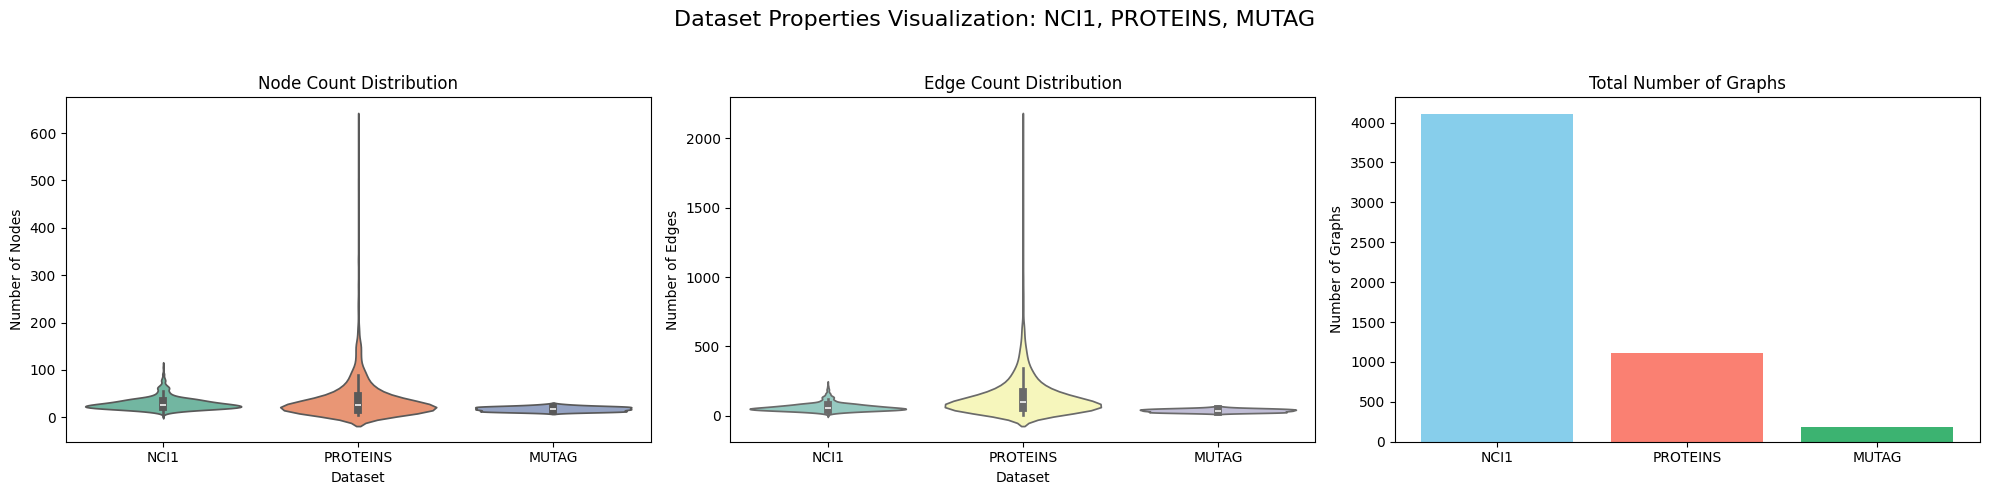

In [ ]:
# Install required libraries
!pip install torch_geometric matplotlib seaborn

# Import necessary libraries
import torch
from torch_geometric.datasets import TUDataset
from torch_geometric.transforms import NormalizeFeatures
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets
datasets = {
    'NCI1': TUDataset(root='/tmp/NCI1', name='NCI1', transform=NormalizeFeatures()),
    'PROTEINS': TUDataset(root='/tmp/PROTEINS', name='PROTEINS', transform=NormalizeFeatures()),
    'MUTAG': TUDataset(root='/tmp/MUTAG', name='MUTAG', transform=NormalizeFeatures())
}

# Function to calculate dataset properties
def calculate_properties(dataset):
    num_nodes = [data.num_nodes for data in dataset]
    num_edges = [data.num_edges for data in dataset]
    total_graphs = len(dataset)
    return {
        'num_nodes': num_nodes,
        'num_edges': num_edges,
        'total_graphs': total_graphs
    }

# Collect properties for each dataset
properties_data = {}
for name, dataset in datasets.items():
    properties_data[name] = calculate_properties(dataset)

# Flatten properties into lists for plotting
all_nodes = sum([[name] * len(properties_data[name]['num_nodes']) for name in datasets.keys()], [])
all_edges = sum([[name] * len(properties_data[name]['num_edges']) for name in datasets.keys()], [])
num_nodes = sum([properties_data[name]['num_nodes'] for name in datasets.keys()], [])
num_edges = sum([properties_data[name]['num_edges'] for name in datasets.keys()], [])
total_graphs = [properties_data[name]['total_graphs'] for name in datasets.keys()]

# Initialize figure
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle("Dataset Properties Visualization: NCI1, PROTEINS, MUTAG", fontsize=16)

# Violin plot for number of nodes per graph
sns.violinplot(x=all_nodes, y=num_nodes, ax=axes[0], palette="Set2")
axes[0].set_title('Node Count Distribution')
axes[0].set_xlabel('Dataset')
axes[0].set_ylabel('Number of Nodes')

# Violin plot for number of edges per graph
sns.violinplot(x=all_edges, y=num_edges, ax=axes[1], palette="Set3")
axes[1].set_title('Edge Count Distribution')
axes[1].set_xlabel('Dataset')
axes[1].set_ylabel('Number of Edges')

# Bar chart for total number of graphs in each dataset
axes[2].bar(datasets.keys(), total_graphs, color=['skyblue', 'salmon', 'mediumseagreen'])
axes[2].set_title('Total Number of Graphs')
axes[2].set_ylabel('Number of Graphs')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Processing...
Done!
Processing...
Done!
Processing...
Done!
<ipython-input-3-3803083c859f>:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(x=all_nodes, y=num_nodes, ax=axes[0], palette=custom_palette, jitter=0.2, alpha=0.8, size=4, linewidth=0.6, edgecolor='gray')
<ipython-input-3-3803083c859f>:46: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(x=all_nodes, y=num_nodes, ax=axes[0], palette=custom_palette, jitter=0.2, alpha=0.8, size=4, linewidth=0.6, edgecolor='gray')
<ipython-input-3-3803083c859f>:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(x=all_edges, y=num_edges, ax=axes[1], palette=

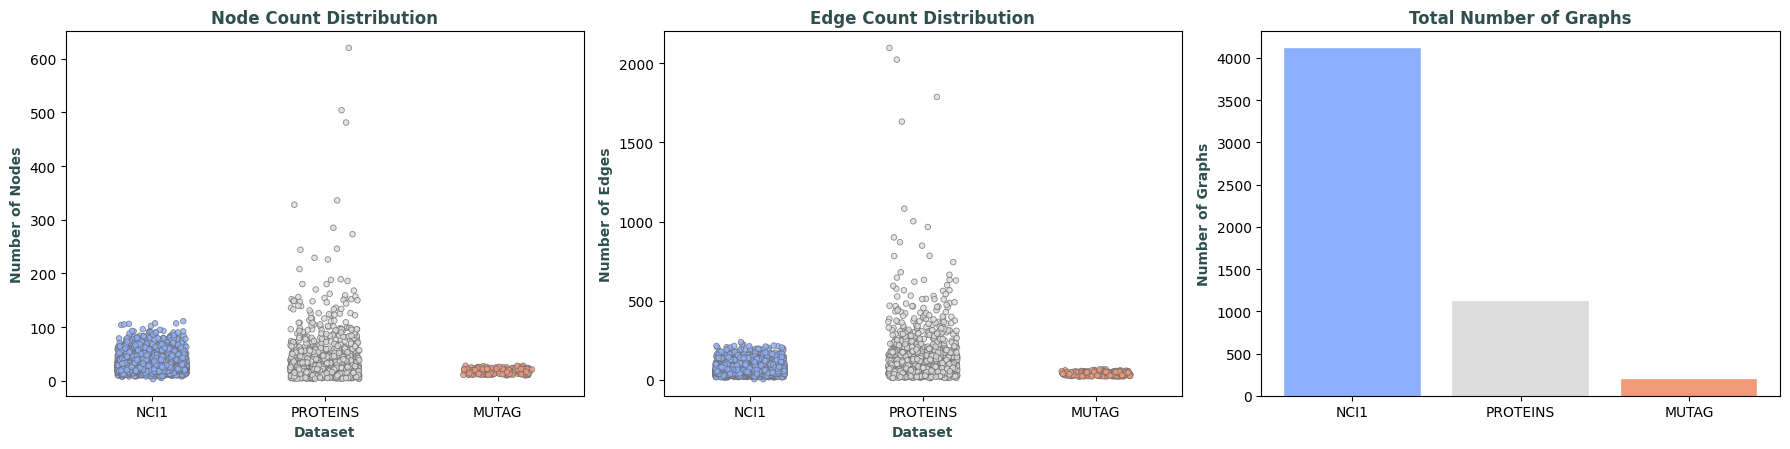

In [ ]:
# Import necessary libraries
import torch
from torch_geometric.datasets import TUDataset
from torch_geometric.transforms import NormalizeFeatures
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets
datasets = {
    'NCI1': TUDataset(root='/tmp/NCI1', name='NCI1', transform=NormalizeFeatures()),
    'PROTEINS': TUDataset(root='/tmp/PROTEINS', name='PROTEINS', transform=NormalizeFeatures()),
    'MUTAG': TUDataset(root='/tmp/MUTAG', name='MUTAG', transform=NormalizeFeatures())
}

# Function to calculate dataset properties
def calculate_properties(dataset):
    num_nodes = [data.num_nodes for data in dataset]
    num_edges = [data.num_edges for data in dataset]
    total_graphs = len(dataset)
    return {
        'num_nodes': num_nodes,
        'num_edges': num_edges,
        'total_graphs': total_graphs
    }

# Collect properties for each dataset
properties_data = {}
for name, dataset in datasets.items():
    properties_data[name] = calculate_properties(dataset)

# Flatten properties into lists for plotting
all_nodes = sum([[name] * len(properties_data[name]['num_nodes']) for name in datasets.keys()], [])
all_edges = sum([[name] * len(properties_data[name]['num_edges']) for name in datasets.keys()], [])
num_nodes = sum([properties_data[name]['num_nodes'] for name in datasets.keys()], [])
num_edges = sum([properties_data[name]['num_edges'] for name in datasets.keys()], [])
total_graphs = [properties_data[name]['total_graphs'] for name in datasets.keys()]

# Set a custom color palette
custom_palette = sns.color_palette("coolwarm", len(datasets))

# Initialize figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("", fontsize=16, weight='bold', color="midnightblue")

# Strip plot for number of nodes per graph
sns.stripplot(x=all_nodes, y=num_nodes, ax=axes[0], palette=custom_palette, jitter=0.2, alpha=0.8, size=4, linewidth=0.6, edgecolor='gray')
axes[0].set_title('Node Count Distribution', weight='bold', color="darkslategray")
axes[0].set_xlabel('Dataset', weight='bold', color="darkslategray")
axes[0].set_ylabel('Number of Nodes', weight='bold', color="darkslategray")

# Strip plot for number of edges per graph
sns.stripplot(x=all_edges, y=num_edges, ax=axes[1], palette=custom_palette, jitter=0.2, alpha=0.8, size=4, linewidth=0.6, edgecolor='gray')
axes[1].set_title('Edge Count Distribution', weight='bold', color="darkslategray")
axes[1].set_xlabel('Dataset', weight='bold', color="darkslategray")
axes[1].set_ylabel('Number of Edges', weight='bold', color="darkslategray")

# Bar chart with gradient colors for total number of graphs
bars = axes[2].bar(datasets.keys(), total_graphs, color=custom_palette)
axes[2].set_title('Total Number of Graphs', weight='bold', color="darkslategray")
axes[2].set_ylabel('Number of Graphs', weight='bold', color="darkslategray")

# Add gradient effect to bar colors
for bar, color in zip(bars, custom_palette):
    bar.set_edgecolor(color)
    bar.set_linewidth(1.2)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
